# Two states and their overlap

This notebook draws two states of a spin $J$ (dimension $N = 2J+1$) and computes their overlap
$|\langle\phi|\psi\rangle|^2$, using the C++ class `spin::Qudit` through the Python module `spinlib`.
The two example states are

$$|\phi\rangle = |J, J\rangle, \qquad |\psi\rangle = \frac{1}{\sqrt{2J+1}} \sum_{m=-J}^{J} |J, m\rangle_y ,$$

the coherent state along $+z$ and the equal-weight superposition of all the Dicke states along $y$, i.e. the
reference state $|o\rangle$ of the qudit ruler (Part I, Eq. 45 with all phases $\varphi_{m_y} = 0$).
To study other states, change only the cell of section 3.1 that builds them.

| Section | What it does |
|---|---|
| 1. Setup | imports `spinlib` (built by `notebook_cpy_playground.ipynb`) |
| 2. Plotting functions | Bloch sphere and populations |
| 3. The two states | builds them and draws them |
| 4. Overlap | $\lvert\langle\phi\lvert\psi\rangle\rvert^2$, as a number and as curves |

**Basis convention.** Index $k = 0,\dots,N-1$ is the Dicke state $|J, m\rangle$ with $m = J - k$, so
$|J,J\rangle = (1, 0, \dots, 0)$.

## 1. Setup

This notebook only **imports** the Python module `spinlib`: it is built from the C++ sources in `../src_cpp` by
section 1 of `notebook_cpy_playground.ipynb`. Run that section once before this notebook, and again after any
change to `qudit.hpp` or `spin_bindings.cpp` (then restart this kernel too).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go            # preinstalled on Colab; otherwise:  %pip install plotly

# Folder where notebook_cpy_playground.ipynb built spinlib (relative to this notebook, or an absolute path).
SRC = os.path.abspath("../src_cpp")
sys.path.insert(0, SRC)                      # Python looks for modules in the folders of sys.path: add SRC
import spinlib                               # ModuleNotFoundError: run section 1 of the playground notebook first

## 2. Plotting functions

* `bloch_figure(q, title)`: the state on the Bloch sphere, coloured with its **Husimi function**
  $Q(\theta,\varphi) = |\langle\theta,\varphi|\psi\rangle|^2$ (the overlap with the coherent state pointing at
  $(\theta,\varphi)$), with a red arrow along $\langle\vec S\rangle$. Interactive: drag to rotate, hover to read $Q$.
* `plot_populations(states, labels)`: the populations $|\langle J,m|\psi\rangle|^2$ of each state in the $S_z$
  basis, as bars side by side.

In [2]:
def bloch_traces(q, n_theta=61, n_phi=121, cmax=None):
    # Sphere coloured with the Husimi function Q (computed in C++), and a red arrow along <S>.
    TH, PH = np.meshgrid(np.linspace(0, np.pi, n_theta), np.linspace(0, 2*np.pi, n_phi), indexing="ij")
    x, y, z = np.sin(TH)*np.cos(PH), np.sin(TH)*np.sin(PH), np.cos(TH)
    Q = np.asarray(q.husimiQ(n_theta, n_phi), dtype=float)
    sphere = go.Surface(x=x, y=y, z=z, surfacecolor=Q, cmin=0, cmax=Q.max() if cmax is None else cmax,
                        colorscale="Viridis", colorbar=dict(title="Q", len=0.6))
    s = np.asarray(q.avgSpin(), dtype=float)                                   # mean spin <S>
    u = s / np.linalg.norm(s) if np.linalg.norm(s) > 1e-9 else np.zeros(3)     # unit vector (0 if <S> = 0)
    arrow = go.Scatter3d(x=[u[0], 1.3*u[0]], y=[u[1], 1.3*u[1]], z=[u[2], 1.3*u[2]],
                         mode="lines", line=dict(color="red", width=8), hoverinfo="skip")
    return [sphere, arrow]


def bloch_figure(q, title="", **grid):
    # The traces above plus the x, y, z axes, in a cube with hidden coordinate planes.
    axes = [go.Scatter3d(x=[-1.35*a[0], 1.35*a[0]], y=[-1.35*a[1], 1.35*a[1]], z=[-1.35*a[2], 1.35*a[2]],
                         mode="lines+text", text=["", name], line=dict(color="gray", width=2), hoverinfo="skip")
            for a, name in [((1, 0, 0), "x"), ((0, 1, 0), "y"), ((0, 0, 1), "z")]]
    fig = go.Figure(bloch_traces(q, **grid) + axes)
    hidden = dict(visible=False)
    fig.update_layout(title=title, showlegend=False, height=450, margin=dict(l=0, r=0, t=40, b=0),
                      scene=dict(xaxis=hidden, yaxis=hidden, zaxis=hidden, aspectmode="cube",
                                 camera=dict(eye=dict(x=1.15, y=0.85, z=0.65))))
    return fig

In [3]:
def plot_populations(states, labels):
    # Bars of |<J,m|psi>|^2 against m, one colour per state, slightly shifted so that they do not overlap.
    width = 0.8 / len(states)
    plt.figure(figsize=(8, 3.5))
    for i, (q, label) in enumerate(zip(states, labels)):
        m = np.array([q.spinM(k) for k in range(q.dim())])
        plt.bar(m + (i - (len(states) - 1) / 2) * width, np.abs(q.state())**2, width=width, label=label)
    plt.xlabel(r"$m$"); plt.ylabel(r"$|\langle J,m|\cdot\rangle|^2$"); plt.legend(); plt.tight_layout(); plt.show()

## 3. The two states

### 3.1 Building them
* $|\phi\rangle = |J,J\rangle$ is the named state `"CSS+Z"`.
* $|\psi\rangle$ is built in Python: add the amplitude vectors of the $N$ Dicke states `prepareDickeY(k)`,
  $k = 0, \dots, N-1$, and load the sum with `setState`, which normalises it. The library also prepares it
  directly with `prepareReference()`: the two must agree (printed below).

**Normalisation.** The $|J,m\rangle_y$ are orthonormal, so the sum of all of them has norm$^2 = 2J+1$:
the normalisation factor is $1/\sqrt{2J+1}$ (printed below as a check).

**Phases.** Each Dicke state is defined only up to a global phase, and the sum depends on those phases.
`spinlib` follows the paper (after Eq. 43): the ladder operators along $y$ are $S^\pm_{(y)} = S_z \pm iS_x$, with
real positive matrix elements, i.e. the cyclic frame $(z, x, y)$. By construction,
$|J,m\rangle_y = e^{-i\frac{\pi}{2}S_z}\,e^{-i\frac{\pi}{2}S_y}\,e^{-i\pi S_z}\,|J,m\rangle$, a rotation that takes
$z \to y$ and $x \to z$: the state with all amplitudes equal to $1$, which points along $+x$, goes to $+z$, so
$|\psi\rangle$ points to $+z$. A different convention gives a different $|\psi\rangle$
(without the $e^{-i\pi S_z}$, for instance, the same sum points to $-z$).

In [4]:
N = 21                                        # dimension: spin J = 10
J = (N - 1) / 2

# |phi> = |J, J>
phi = spinlib.Qudit(N, "CSS+Z")

# |psi> = sum_m |J, m>_y / sqrt(2J+1)
q = spinlib.Qudit(N)                                                   # work qudit for the Dicke states
amplitudes = sum(np.asarray(q.prepareDickeY(k).state()) for k in range(N))
print("norm^2 of the sum =", round(np.linalg.norm(amplitudes)**2, 10), "  (2J+1 =", N, ")\n")
psi = spinlib.Qudit(N)
psi.setState(amplitudes)                      # normalises: divides by sqrt(2J+1)
reference = spinlib.Qudit(N).prepareReference()
print("max |psi - prepareReference()| =", np.abs(psi.state() - reference.state()).max(), "\n")

phi.printSpin("phi")
psi.printSpin("psi")

norm^2 of the sum = 21.0   (2J+1 = 21 )

max |psi - prepareReference()| = 1.1102230246251565e-16 

phi :  <psi|psi> = 1
    <Sx> = 0	Var(Sx) = 5
    <Sy> = 0	Var(Sy) = 5
    <Sz> = 10	Var(Sz) = 0
psi :  <psi|psi> = 1
    <Sx> = -1.03225e-32	Var(Sx) = 0.622851
    <Sy> = -1.88111e-16	Var(Sy) = 36.6667
    <Sz> = 8.15622	Var(Sz) = 6.18663


### 3.2 Drawing them
On the sphere, $|\phi\rangle$ is a round spot on the north pole. $|\psi\rangle$ is centred on the north pole
too, but stretched along the great circle through $\pm y$ (large $\mathrm{Var}(S_y)$, small $\mathrm{Var}(S_x)$ in
3.1). The bars compare the two states in the $S_z$ basis: $|\psi\rangle$ populates only
$m = J, J-2, J-4, \dots$

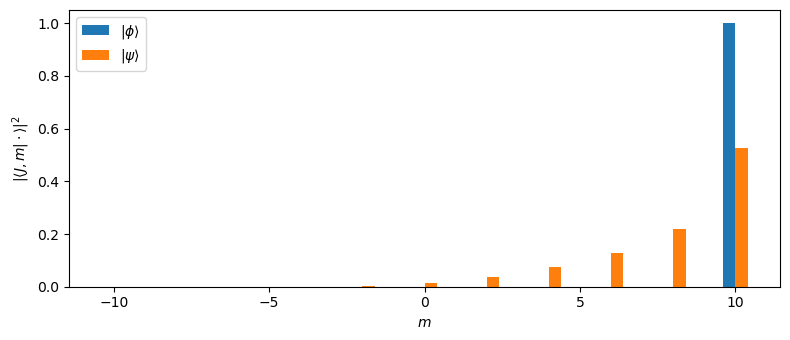

In [5]:
bloch_figure(phi, "|φ⟩ = |J, J⟩").show()
bloch_figure(psi, "|ψ⟩ = Σ_m |J, m⟩_y / √(2J+1)").show()
plot_populations([phi, psi], [r"$|\phi\rangle$", r"$|\psi\rangle$"])

## 4. Overlap

### 4.1 The number
`overlap(a, b)` computes $\langle a|b\rangle = \sum_k a_k^*\, b_k$ from the two amplitude vectors
(`np.vdot` conjugates its first argument). Since $|\phi\rangle = |J,J\rangle$ is the coherent state at the north
pole, $|\langle\phi|\psi\rangle|^2$ is also the Husimi function of $|\psi\rangle$ at $\theta = 0$, i.e.
$|$`psi.overlapCSS(0, 0)`$|^2$: the two numbers printed below must agree.

In [6]:
def overlap(a, b):
    # <a|b> for two qudits of the same dimension.
    return np.vdot(a.state(), b.state())

print("|<phi|psi>|^2           =", abs(overlap(phi, psi))**2)
print("|<0,0|psi>|^2 (Husimi)  =", abs(psi.overlapCSS(0, 0))**2)

|<phi|psi>|^2           = 0.5262783179496712
|<0,0|psi>|^2 (Husimi)  = 0.5262783179496712


### 4.2 The overlap as a curve
Two ways to see the overlap change:

* **with $J$**: $|\langle\phi|\psi\rangle|^2$ for every $J$ from $1/2$ to $30$. It is $1$ for a spin $1/2$
  (the equal superposition of the states along $\pm y$ is the state along $+z$) and decreases slowly with $J$;
* **turning $|\phi\rangle$**: the overlap of $|\psi\rangle$ with the coherent state $|\theta, \varphi\rangle$, i.e.
  $|\phi\rangle$ tilted from the north pole ($\theta = 0$) to the south pole ($\theta = \pi$), towards $x$ ($\varphi = 0$)
  and towards $y$ ($\varphi = \pi/2$).
  This is a cut of the Husimi function drawn on the sphere in 3.2: it goes from $|\langle\phi|\psi\rangle|^2$
  at $\theta = 0$ to the weight of $|J,-J\rangle$ at $\theta = \pi$ (tiny for integer $J$, zero for half-integer $J$).
  Towards $x$ it drops quickly, towards $y$ slowly: the stretching seen on the sphere.

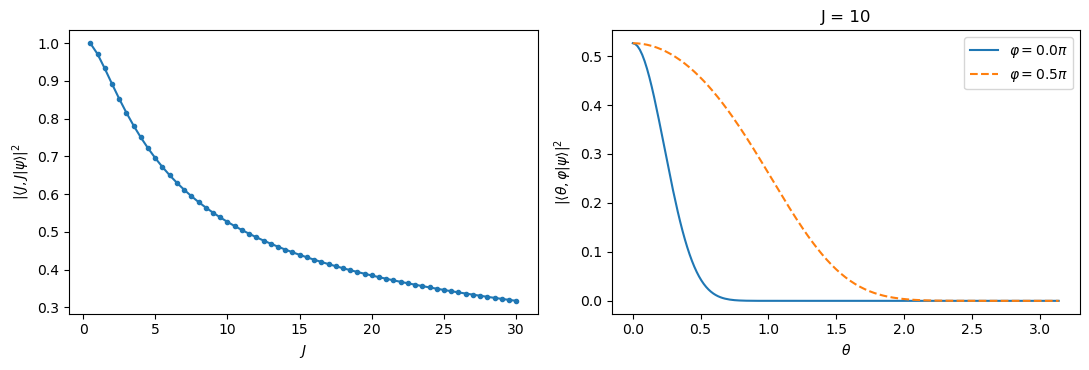

In [7]:
dims = np.arange(2, 62)                       # N = 2 ... 61, i.e. J = 1/2 ... 30
overlaps = [abs(overlap(spinlib.Qudit(n, "CSS+Z"), spinlib.Qudit(n).prepareReference()))**2 for n in dims]

thetas = np.linspace(0, np.pi, 181)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot((dims - 1) / 2, overlaps, "o-", ms=3)
ax1.set_xlabel(r"$J$"); ax1.set_ylabel(r"$|\langle J,J|\psi\rangle|^2$")
for ph, style in [(0, "-"), (np.pi/2, "--")]:
    ax2.plot(thetas, [abs(psi.overlapCSS(th, ph))**2 for th in thetas], style, label=fr"$\varphi = {ph/np.pi:.1f}\pi$")
ax2.set_xlabel(r"$\theta$"); ax2.set_ylabel(r"$|\langle\theta,\varphi|\psi\rangle|^2$")
ax2.set_title(f"J = {J:g}"); ax2.legend()
plt.tight_layout(); plt.show()